# Reconstruction vs contrastive vs prediction

The pre-registered design, the hypotheses and their thresholds are in `experiments/recon_vs_pred/README.md`, which was written before any learner was trained.

**Question.** Does a prediction objective keep a dynamical regime that a reconstruction objective loses? If so, is the reason that it drops what it cannot predict?

**Manipulation.** One regime-independent nuisance is added to the observation. Its timescale is either fast (forgotten before the prediction target) or slow (persists into the target), at amplitude σ_n = 1 or 2, plus a no-nuisance condition N0.

This notebook only *displays* results that were computed elsewhere:
- `python experiments/recon_vs_pred/run.py pilot` runs the local, exploratory pilot;
- `python experiments/recon_vs_pred/run.py hpc <runs dir>` scores the confirmatory HPC sweep.

Set `MODE` to choose which results are shown.

In [1]:
import os, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "experiments/recon_vs_pred")
import cpbench
from cpbench.data import Dataset
from design import CONDITIONS, dataset, W
from experiment import verdicts, PRED, RECON
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)

MODE = os.environ.get("CPBENCH_MODE", "pilot")      # ✏️ "pilot" (exploratory) or "hpc" (confirmatory)
df = pd.read_csv(f"cpbench_results/recon_vs_pred_{MODE}.csv")
df["nuis_r2"] = df.nuis_r2.clip(lower=0)            # negative R^2 = no information (ridge overfit on raw features)
print(MODE, len(df), "rows;", sorted(df.cond.unique()), "seeds", sorted(df.seed.unique()))

pilot 30 rows; ['F2', 'N0', 'S2'] seeds [0]


## 1. The data

Each panel shows the first 400 samples of three of the 64 channels in one condition. The coloured band marks the regime. The nuisance is invisible in N0, wiggles quickly in F2 and drifts slowly in S2.

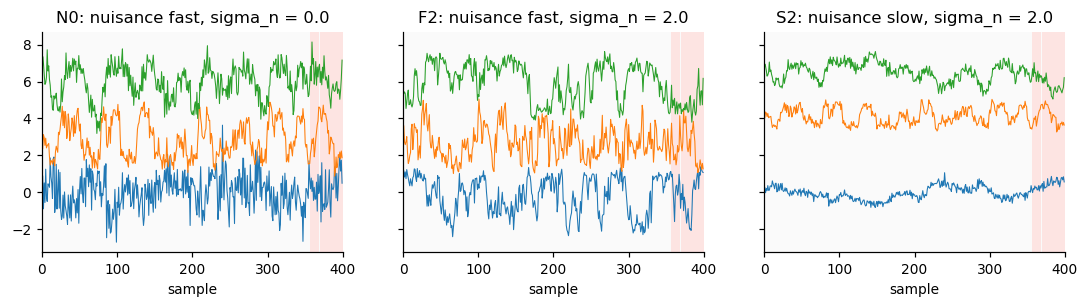

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.6), sharey=True)
for ax, c in zip(axes, ("N0", "F2", "S2")):
    d = Dataset(dataset(c, quick=True)).sample(1, 1200, np.random.default_rng(0))
    for j in range(3):
        ax.plot(d["obs"][0, :400, j] + 3 * j, lw=0.7)
    ax.pcolorfast((0, 400), ax.get_ylim(), d["S_s"][:, :400], cmap="Pastel1", alpha=0.35)
    ax.set_title(f"{c}: nuisance {CONDITIONS[c][0]}, sigma_n = {CONDITIONS[c][1]}"); ax.set_xlabel("sample")
plt.show()

## 2. Verdicts (pre-registered thresholds)

In pilot mode these verdicts are exploratory: one seed and 3k steps. Only the HPC run decides H1–H4.

In [3]:
verdicts(df)

,test,verdict,numbers
0,gate: oracle HMM acc >= 0.95 everywhere,pass,"N0 0.963, F2 0.963, S2 0.963"
1,gate: some trained learner has probe >= 0.9 on N0,pass,best jepa_shared 0.987
2,"gate: no collapse (eff_rank > 2, final loss < loss at 1k)",FAIL,F2 cpc s0 rank 1.1 drop 0.99
3,control F2: family probe - untrained probe (0.558) >= 0.05,info,"pred +0.427, recon -0.060"
4,control N0: family probe - untrained probe (0.749) >= 0.05,info,"pred +0.235, recon -0.263"
5,control S2: family probe - untrained probe (0.558) >= 0.05,info,"pred +0.426, recon -0.085"
6,"H1: F2 probe(pred) - probe(recon) >= 0.10, CI > 0",supported,"diff +0.487, 95% CI [+0.480, +0.495]"
7,"H2: nuisance R2 pred F2 <= 0.3, S2 >= 0.6; recon >= 0.6 on both",inconclusive,pred F2 0.146 S2 0.171; recon F2 0.679 S2 0.840
8,H3: HMM acc pred F2 >= 0.80 and >= S2 + 0.15,supported,"pred F2 0.968, S2 0.546"
9,H4 (exploratory): F2 nuisance R2 ts2vec - cpc >= 0.3,not consistent,"ts2vec 0.169, cpc 0.353, jepa 0.146, ae/vae 0.679"


## 3. All numbers (mean ± sd over seeds)

| Column | What it measures | Reference |
|---|---|---|
| `probe` | linear probe of the regime | chance 0.5 |
| `probe_mlp` | MLP probe on window pairs, secondary | — |
| `nuis_r2` | how much of the nuisance the features carry | 0 = none, 1 = all |
| `hmm` | unsupervised clustering accuracy, primary | — |
| `gmm` | unsupervised clustering accuracy, secondary | — |

In [4]:
cols = ["probe", "probe_mlp", "nuis_r2", "hmm", "gmm"]
order = ["ae", "vae", "jepa_separate", "jepa_shared", "cpc", "ts2vec", "untrained", "raw_flat", "raw_lagcov", "oracle"]
g = df.groupby(["cond", "learner"])[cols]
tab = g.mean().round(3).astype(str) + np.where(g.count() > 1, " ± " + g.std().round(2).astype(str), "")
tab = tab.reset_index().pivot(index="learner", columns="cond").reindex(order).dropna(how="all")
tab

probe               probe_mlp               nuis_r2                hmm                  gmm              
cond              F2     N0     S2        F2     N0     S2      F2   N0     S2     F2     N0     S2     F2     N0     S2
learner                                                                                                                 
ae             0.496  0.492  0.476     0.873  0.967   0.95   0.661  0.0  0.875  0.543  0.971  0.535  0.541  0.968  0.536
vae              0.5   0.48  0.469      0.89  0.975  0.954   0.697  0.0  0.805  0.966  0.971  0.547  0.941  0.969  0.543
jepa_separate   0.98   0.98  0.982     0.975   0.98  0.979   0.184  0.0    0.0  0.967  0.968  0.553  0.966  0.967  0.554
jepa_shared     0.99  0.987  0.986     0.976  0.981  0.984   0.109  0.0  0.343   0.97  0.971  0.539  0.968   0.97  0.542
cpc            0.554  0.976  0.499     0.589  0.969  0.532   0.353  0.0    0.0  0.493  0.964  0.511  0.492  0.962    0.5
ts2vec          0.91  0.877  0.939     0.938  0.913  0.954   0.169  0.0  0.111  0.542  0.963  0.534  0.584  0.817  0.525
untrained      0.558  0.749  0.558     0.525  0.795  0.594   0.212  0.0  0.686  0.516  0.553  0.527  0.515  0.545  0.528
raw_flat       0.474  0.497  0.487     0.745  0.966  0.738   0.915  0.0  0.981  0.514   0.97  0.533  0.516  0.966  0.536
raw_lagcov     0.989  0.992  0.987     0.981  0.993  0.992     0.0  0.0    0.0   0.97  0.971  0.971  0.969   0.97  0.971
oracle          0.99   0.99   0.99     0.984  0.984  0.984     0.0  0.0    0.0  0.963  0.963  0.963  0.968  0.968  0.968

## 4. What each learner keeps

Each point is one run. The x-axis shows how much of the nuisance the features carry, and the y-axis how much of the regime (linear probe).

Hypothesis H2 predicts:
- **prediction** (JEPA) sits to the left in F2, because it drops the fast nuisance, and moves right in S2;
- **reconstruction** (AE, VAE) sits to the right in both.

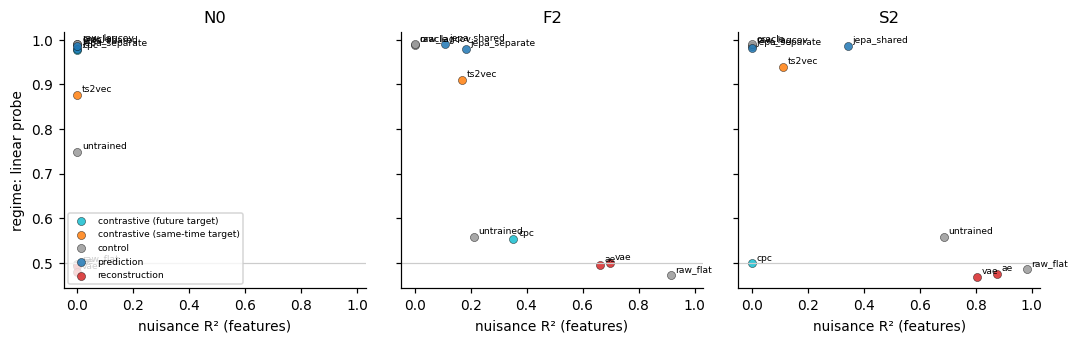

In [5]:
COL = {"reconstruction": "tab:red", "prediction": "tab:blue", "contrastive (future target)": "tab:cyan",
       "contrastive (same-time target)": "tab:orange", "control": "0.6"}
conds = [c for c in CONDITIONS if c in set(df.cond)]
fig, axes = plt.subplots(1, len(conds), figsize=(3.3 * len(conds), 3.2), sharey=True, sharex=True)
for ax, c in zip(np.atleast_1d(axes), conds):
    for fam, sub in df[df.cond == c].groupby("family"):
        ax.scatter(sub.nuis_r2, sub.probe, color=COL[fam], s=28, label=fam, alpha=0.85, edgecolor="k", lw=0.3)
        for r in sub.drop_duplicates("learner").itertuples():
            ax.annotate(r.learner, (r.nuis_r2, r.probe), fontsize=6, xytext=(3, 2), textcoords="offset points")
    ax.axhline(0.5, color="0.8", lw=0.8); ax.set_title(c); ax.set_xlabel("nuisance R² (features)")
np.atleast_1d(axes)[0].set_ylabel("regime: linear probe"); np.atleast_1d(axes)[0].legend(fontsize=6, loc="lower left")
plt.tight_layout(); plt.show()

## 5. Retention versus clusterability

Each panel compares the regime probe (bars) with unsupervised HMM accuracy (black dots). A large gap means the regime is in the features but not in a form that can be clustered.

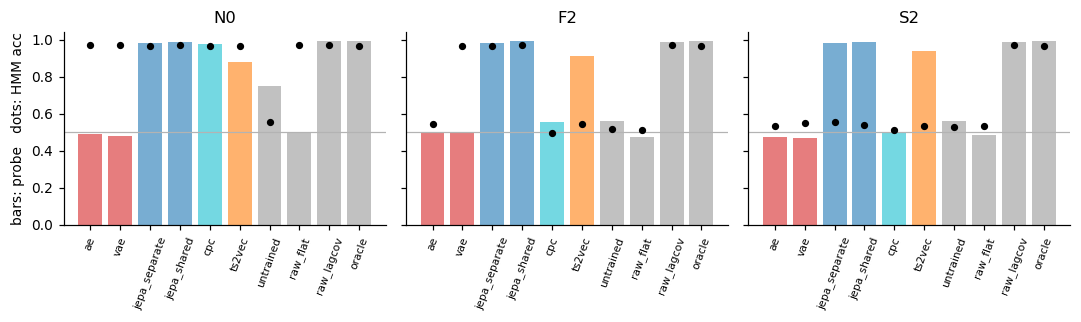

In [6]:
lead = [l for l in order if l in set(df.learner)]
fig, axes = plt.subplots(1, len(conds), figsize=(3.3 * len(conds), 3.0), sharey=True)
for ax, c in zip(np.atleast_1d(axes), conds):
    m = df[df.cond == c].groupby("learner")[["probe", "hmm"]].mean().reindex(lead)
    x = np.arange(len(m))
    ax.bar(x, m.probe, color=[COL[df[df.learner == l].family.iloc[0]] for l in m.index], alpha=0.6)
    ax.scatter(x, m.hmm, color="k", s=14, zorder=3)
    ax.set_xticks(x, m.index, rotation=70, fontsize=7); ax.axhline(0.5, color="0.7", lw=0.8); ax.set_title(c)
np.atleast_1d(axes)[0].set_ylabel("bars: probe   dots: HMM acc")
plt.tight_layout(); plt.show()

## 6. Dose response (needs all five conditions: the HPC run)

Each metric is plotted against the nuisance amplitude σ_n (0, 1, 2). Solid lines are fast nuisance and dashed lines slow nuisance.

In [7]:
if set(CONDITIONS) <= set(df.cond):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    for ax, m in zip(axes, ("probe", "nuis_r2", "hmm")):
        for l in ["ae", "vae", "jepa_separate", "jepa_shared", "cpc", "ts2vec"]:
            fam = df[df.learner == l].family.iloc[0]
            for speed, ls in (("fast", "-"), ("slow", "--")):
                sub = df[(df.learner == l) & ((df.speed == speed) | (df.cond == "N0"))].groupby("sigma_n")[m].mean()
                ax.plot(sub.index, sub.values, ls, color=COL[fam], marker="o", ms=3, label=l if speed == "fast" else None)
        ax.set_xlabel("nuisance sigma_n"); ax.set_title(m)
    axes[0].legend(fontsize=6); plt.tight_layout(); plt.show()
else:
    print("pilot: only", conds)

pilot: only ['N0', 'F2', 'S2']
